# Partner Course Kit - ML Research XGBoost Sector Rotation

This notebook explores the ML XGBoost (Gradient Boosting) approach to sector rotation over 9 U.S. sector ETFs. The pedagogical scope goes beyond gradient boosting mechanics: this notebook honestly measures what a regression model can — and cannot — extract from a noisy sector momentum signal.

**Objective**: identify the hyperparameters and features of the regression GBM (target: 20-day forward return) and measure, against the "predict the mean" floor, what the model really adds. The reference `main.py` backtest (kit README) reaches **Sharpe 0.521, CAGR 12.81%, MaxDD 39.1%** over the frozen 2015-2024 window: the notebook explains where that performance comes from — and why it does not come from the model's R².

**Research plan**:
1. Sector data exploration (buy-and-hold benchmark)
2. Feature engineering (20 technical indicators)
3. Iteration 1: GBM baseline (100 trees, depth 4, lr=0.05)
4. Iteration 2: Optimized GBM (selected features, tuned lr)
5. Prediction analysis by regime (bull/bear)
6. Calibration towards main.py
7. Conclusion and iteration paths

**Environment note**: this notebook uses QuantBook (QuantConnect Cloud environment). The window is **frozen** at 2015-01-01 -> 2025-01-01 (end excluded), identical to the `main.py` backtest — the outputs are the true outputs of the reference run.

In [1]:
from AlgorithmImports import *
from datetime import datetime
qb = QuantBook()

# Fixed data window, same bounds as the kit backtest (main.py: 2015-01-01 -> 2024-12-31)
START = datetime(2015, 1, 1)
END = datetime(2025, 1, 1)

# Universe: 9 sector ETFs + SPY benchmark
tickers = ["XLK", "XLF", "XLV", "XLE", "XLY", "XLP", "XLI", "XLU", "XLRE"]
symbols = {}
for t in tickers:
    symbols[t] = qb.add_equity(t, Resolution.DAILY).symbol
spy = qb.add_equity("SPY", Resolution.DAILY).symbol

print(f"Universe: {len(tickers)} sector ETFs + SPY")
print(f"Tickers: {', '.join(tickers)}")
print(f"Data window: {START.date()} -> {END.date()} (end excluded)")

Universe: 9 sector ETFs + SPY
Tickers: XLK, XLF, XLV, XLE, XLY, XLP, XLI, XLU, XLRE
Data window: 2015-01-01 -> 2025-01-01 (end excluded)


## 1. Exploring the sector data

The universe covers 9 U.S. sector ETFs + SPY, over the **frozen window** 2015-01-01 -> 2025-01-01 (end excluded), identical to the `main.py` backtest. The exploration does not merely check that the data loads: it establishes the **benchmark**. Each sector has its own return/risk profile, and the annualized Sharpe over the period tells us what a passive *buy-and-hold* strategy would achieve. The ML strategy must beat this benchmark to justify its complexity — otherwise it merely replicates the market while adding noise and transaction costs.

**XLRE, the youngest ETF of the panel, bounds the common window** of comparisons: the cell prints the bars per symbol, the retained common window and the annualized performance table.

In [2]:
# Download daily data over the fixed window (one call for all symbols)
history = qb.history(list(symbols.values()) + [spy], START, END, Resolution.DAILY)
print(f"Data shape: {history.shape}")

# Label columns by ticker (unstack sorts the columns by Symbol, not in the order of `tickers`)
close_prices = history["close"].unstack(level=0)
close_prices.columns = [getattr(c, "value", None) or str(c).split(" ")[0] for c in close_prices.columns]
close_prices = close_prices[tickers + ["SPY"]]
print("First and last bar per symbol:")
for t in close_prices.columns:
    s = close_prices[t].dropna()
    print(f"  {t:<5} {s.index.min().date()} -> {s.index.max().date()} ({len(s)} bars)")
returns = close_prices.pct_change(fill_method=None).dropna()
print(f"\nCommon return window: {returns.index.min().date()} -> {returns.index.max().date()} ({len(returns)} days)")

# Cross-sector return analysis
ann_ret = returns.mean() * 252
ann_vol = returns.std() * np.sqrt(252)
sharpe = ann_ret / ann_vol

# Build the table from the labelled Series (index = tickers)
perf = pd.DataFrame({
    'AnnReturn': ann_ret,
    'AnnVol': ann_vol,
    'Sharpe': sharpe,
}).sort_values('Sharpe', ascending=False)

print("\nPerformance over the common window (annualized, no risk-free rate):")
print(perf.round(3))

Data shape: (24967, 5)
First and last bar per symbol:
  XLK   2015-01-02 -> 2024-12-31 (2516 bars)
  XLF   2015-01-02 -> 2024-12-31 (2516 bars)
  XLV   2015-01-02 -> 2024-12-31 (2516 bars)
  XLE   2015-01-02 -> 2024-12-31 (2516 bars)
  XLY   2015-01-02 -> 2024-12-31 (2516 bars)
  XLP   2015-01-02 -> 2024-12-31 (2516 bars)
  XLI   2015-01-02 -> 2024-12-31 (2516 bars)
  XLU   2015-01-02 -> 2024-12-31 (2516 bars)
  XLRE  2015-10-08 -> 2024-12-31 (2323 bars)
  SPY   2015-01-02 -> 2024-12-31 (2516 bars)

Common return window: 2015-10-09 -> 2024-12-31 (2322 days)

Performance over the common window (annualized, no risk-free rate):
      AnnReturn  AnnVol  Sharpe
XLK       0.228   0.237   0.962
SPY       0.149   0.178   0.840
XLY       0.150   0.216   0.695
XLI       0.137   0.199   0.688
XLF       0.146   0.225   0.650
XLV       0.107   0.166   0.643
XLP       0.088   0.147   0.600
XLU       0.110   0.194   0.569
XLRE      0.087   0.209   0.415
XLE       0.110   0.302   0.365


**Reading the benchmark.** Over the common window 2015-10-09 -> 2024-12-31 (annualized, no risk-free rate): **XLK (Technology) dominates with a Sharpe of 0.962** (22.8% annualized for 23.7% vol), ahead of XLY (0.695) and XLI (0.688). SPY, the passive benchmark, sits at **0.840** — that is the bar to clear. **XLE brings up the rear at 0.365** with the highest volatility (30.2%), and XLRE (0.415) drags its late exchange listing: the first-to-last spread is 1 to 2.6x — the raw material of sector rotation, and a warning against extrapolating a recent regime (the decade smooths the 2023-2024 rally with flat years 2015-2017).

## 2. Feature Engineering (20 indicators)

The XGBoost model uses 20 technical features, 6 more than the RandomForest: on top of the standard indicators (RSI, Bollinger, MACD, Momentum) it adds Stochastic, ATR ratio, 5-day volatility, 1/5/20-day returns and additional SMA ratios. The hypothesis is that these extra features capture the **volatility regime** and short-term dynamics that the RandomForest could not see. This is a hypothesis to confront with the data: if feature importance shows the new variables dominating, the extension was justified; if it is still the same ones (mom_50, vol_20), the contribution is marginal.

In [3]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings('ignore')

def calculate_features(df_candle):
    """Calculate 20 technical features for a single asset."""
    closes = df_candle["close"]
    volumes = df_candle["volume"]
    highs = df_candle["high"]
    lows = df_candle["low"]
    returns = closes.pct_change()

    # SMA
    sma_5 = closes.rolling(5).mean()
    sma_10 = closes.rolling(10).mean()
    sma_20 = closes.rolling(20).mean()
    sma_50 = closes.rolling(50).mean()

    # RSI
    delta = closes.diff()
    gain = delta.where(delta > 0, 0).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))

    # Bollinger Bands
    bb_mid = closes.rolling(20).mean()
    bb_std = closes.rolling(20).std()
    bb_pos = (closes - bb_mid) / (2 * bb_std)

    # MACD
    ema12 = closes.ewm(span=12).mean()
    ema26 = closes.ewm(span=26).mean()
    macd = ema12 - ema26
    macd_signal = macd.ewm(span=9).mean()

    # Stochastic
    low_14 = lows.rolling(14).min()
    high_14 = highs.rolling(14).max()
    denom = (high_14 - low_14).replace(0, np.nan)
    stoch_k = 100 * (closes - low_14) / denom

    # ATR
    tr = pd.concat([
        highs - lows,
        (highs - closes.shift()).abs(),
        (lows - closes.shift()).abs(),
    ], axis=1).max(axis=1)
    atr = tr.rolling(14).mean()

    # Momentum
    mom_5 = closes.pct_change(5)
    mom_10 = closes.pct_change(10)
    mom_20 = closes.pct_change(20)
    mom_50 = closes.pct_change(50)

    # Volatility
    vol_5 = returns.rolling(5).std()
    vol_20 = returns.rolling(20).std()

    # Volume
    vol_sma = volumes.rolling(20).mean()
    volume_ratio = volumes / vol_sma

    # Price ratios
    price_sma20 = closes / sma_20
    price_sma50 = closes / sma_50

    # Range position
    low_50 = lows.rolling(50).min()
    high_50 = highs.rolling(50).max()
    range_pos = (closes - low_50) / (high_50 - low_50)

    features = pd.DataFrame({
        "rsi": rsi, "bb_position": bb_pos, "macd_hist": macd - macd_signal,
        "stoch_k": stoch_k, "atr_ratio": atr / closes,
        "mom_5": mom_5, "mom_10": mom_10, "mom_20": mom_20, "mom_50": mom_50,
        "vol_5": vol_5, "vol_20": vol_20,
        "volume_ratio": volume_ratio,
        "price_sma20": price_sma20, "price_sma50": price_sma50,
        "sma_5_20": sma_5 / sma_20, "sma_10_50": sma_10 / sma_50,
        "range_position": range_pos,
        "return_1d": returns, "return_5d": closes.pct_change(5),
        "return_20d": closes.pct_change(20),
    })
    return features.fillna(0).replace([np.inf, -np.inf], 0)

feature_names = ["rsi", "bb_position", "macd_hist", "stoch_k", "atr_ratio",
    "mom_5", "mom_10", "mom_20", "mom_50", "vol_5", "vol_20",
    "volume_ratio", "price_sma20", "price_sma50", "sma_5_20", "sma_10_50",
    "range_position", "return_1d", "return_5d", "return_20d"]
print(f"Feature engineering defined: {len(feature_names)} features")
print(f"Extra features vs RF: stoch_k, atr_ratio, vol_5, sma_10_50, return_1d, return_5d")

Feature engineering defined: 20 features
Extra features vs RF: stoch_k, atr_ratio, vol_5, sma_10_50, return_1d, return_5d


In [4]:
# Build pooled training dataset (regression target: 20-day forward return)
all_X, all_y = [], []
lookback = 252 * 3  # 3-year window, last 3 years of the fixed window

for ticker in tickers:
    hist = history.loc[symbols[ticker]].tail(lookback)
    if hist.empty or len(hist) < 100:
        continue
    features = calculate_features(hist)
    closes = hist["close"]
    target = closes.pct_change(20).shift(-20)  # regression target
    features["target"] = target
    features = features.dropna()
    if len(features) > 50:
        all_X.append(features.drop("target", axis=1))
        all_y.append(features["target"])

X = pd.concat(all_X, ignore_index=True)
y = pd.concat(all_y, ignore_index=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Training window: {hist.index.min().date()} -> {hist.index.max().date()}")
print(f"Training data: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Target (20d fwd return): mean={y.mean():.4f}, std={y.std():.4f}")
print(f"Target range: [{y.min():.4f}, {y.max():.4f}]")

Training window: 2021-12-29 -> 2024-12-31
Training data: 6624 samples, 20 features
Target (20d fwd return): mean=0.0076, std=0.0564
Target range: [-0.2252, 0.2704]


**Reading the training set.** 6624 samples, 20 features, target = 20-day forward return (window 2021-12-29 -> 2024-12-31, 3 years). The critical statistic is the **target itself**: mean = 0.0076, std = 0.0564, range [-0.2252, +0.2704]. The signal-to-noise ratio is unfavorable — the average 20-day return (~0.76%) is small against its volatility (~5.6%). A model that simply predicted the mean would have an error (RMSE) of about 0.0564. That is the **floor to beat**: the next cell will show whether the GBM does better than this floor, and by how much.

## 3. Iteration 1: GBM Baseline (100 trees, depth 4, lr=0.05)

Reference configuration from `main.py`. We use `GradientBoostingRegressor` in **regression** mode — predicting the continuous future return (rather than a binary up/down classification) differentiates sectors beyond mere positive/negative, and orders signals by strength. The training window is 3 years (756 days): a trade-off between enough data to estimate 20 features and signal relevance (a 2018 market is not a 2024 market). Validation uses 5-fold cross-validation on the training sample.

Parameters: `n_estimators=100`, `max_depth=4`, `learning_rate=0.05`, `min_samples_leaf=15`, `subsample=0.8`.

In [5]:
# Iteration 1: GBM Baseline
gbm1 = GradientBoostingRegressor(
    n_estimators=100, max_depth=4, learning_rate=0.05,
    min_samples_leaf=15, subsample=0.8, random_state=42,
)
gbm1.fit(X_scaled, y)

# Cross-validation (R2 score for regression)
scores_r2 = cross_val_score(gbm1, X_scaled, y, cv=5, scoring='r2')
scores_mse = cross_val_score(gbm1, X_scaled, y, cv=5, scoring='neg_mean_squared_error')

print(f"Iteration 1 - GBM Baseline")
print(f"  5-fold CV R2: {scores_r2.mean():.4f} (+/- {scores_r2.std():.4f})")
print(f"  5-fold CV RMSE: {np.sqrt(-scores_mse.mean()):.4f}")
print(f"  Target std: {y.std():.4f}")
print(f"  RMSE/Target_std ratio: {np.sqrt(-scores_mse.mean()) / y.std():.4f}")

# Feature importance
importance = pd.Series(gbm1.feature_importances_, index=X.columns).sort_values(ascending=True)
print(f"\nTop 5 features:")
for feat, imp in importance.tail(5).items():
    print(f"  {feat}: {imp:.4f}")

Iteration 1 - GBM Baseline
  5-fold CV R2: 0.0425 (+/- 0.0830)
  5-fold CV RMSE: 0.0553
  Target std: 0.0564
  RMSE/Target_std ratio: 0.9802

Top 5 features:
  volume_ratio: 0.0556
  vol_20: 0.1120
  mom_50: 0.1469
  atr_ratio: 0.1474
  sma_10_50: 0.1642


**Reading the baseline R² — a weak signal, honestly measured.** The 5-fold CV R² is **0.0425** (±0.0830). For context, an R² of 0 means "as good as predicting the mean"; the interval (±0.0830) **spans 0** — the R² is statistically indistinguishable from zero. The RMSE of **0.0553** against a target_std of 0.0564 gives a ratio of **0.9802**: the model reduces error by only ~2% relative to the "predict the mean" floor. Plainly, **the GBM learns almost nothing** from the sector momentum signal on this target.

The most important features (`sma_10_50`: 0.164, `atr_ratio`: 0.147, `mom_50`: 0.147, `vol_20`: 0.112) answer the §2 hypothesis: the features **added** vs the RF (atr_ratio, sma_10_50) rank at the top — the extension was not useless, but the overall predictive power remains marginal. This is not a model failure — it is the reality of the signal: 20-day sector returns are dominated by noise, not by observable technical features. Same caveat as the RF kit: the CV splits the pooled set into contiguous ticker blocks (`KFold` without shuffle, since the GBM is a regressor) with overlapping targets — an optimistic reading.

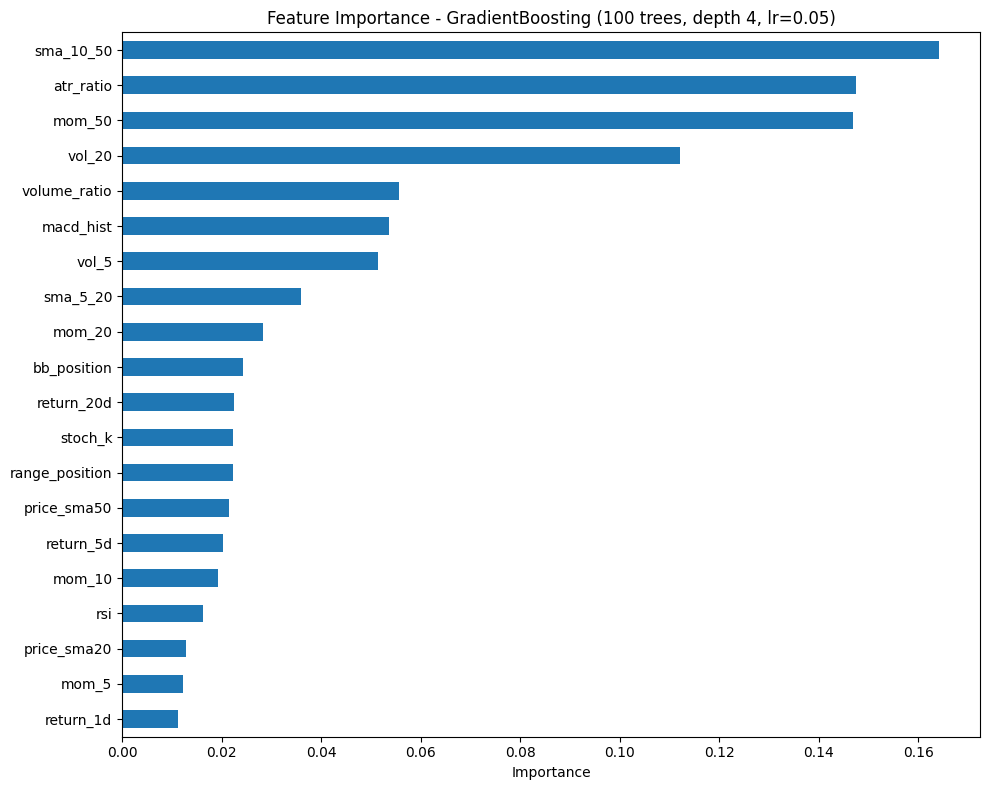

In [6]:
# Feature importance plot
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
importance.plot.barh(ax=ax)
ax.set_title('Feature Importance - GradientBoosting (100 trees, depth 4, lr=0.05)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## 4. Iteration 2: Optimized GBM (tuned lr, selected features)

The second iteration pulls two classic optimization levers: (1) **feature selection** — keep only features with importance > 0.03 to reduce noise and overfitting; (2) **more aggressive lr** (0.1 vs 0.05) with more trees (200 vs 100) and a lower subsample (0.7 vs 0.8) for more randomness. The intent is to improve generalization. The next cell's verdict is **counter-intuitive and honest**: this "optimization" degrades performance, and that is a lesson as valuable as a success.

In [7]:
# Iteration 2: Feature selection + adjusted learning rate
top_features = importance[importance > 0.03].index.tolist()
print(f"Selected {len(top_features)}/{len(X.columns)} features (importance > 0.03):")
print(f"  Features: {top_features}")

X_selected = X[top_features]
scaler2 = StandardScaler()
X_sel_scaled = scaler2.fit_transform(X_selected)

# GBM with adjusted params
gbm2 = GradientBoostingRegressor(
    n_estimators=200, max_depth=4, learning_rate=0.1,
    min_samples_leaf=15, subsample=0.7, random_state=42,
)
gbm2.fit(X_sel_scaled, y)

scores2_r2 = cross_val_score(gbm2, X_sel_scaled, y, cv=5, scoring='r2')
scores2_mse = cross_val_score(gbm2, X_sel_scaled, y, cv=5, scoring='neg_mean_squared_error')

print(f"\nIteration 2 - GBM Optimized")
print(f"  Features: {len(top_features)}")
print(f"  n_estimators: 200 (vs 100), lr: 0.1 (vs 0.05), subsample: 0.7 (vs 0.8)")
print(f"  5-fold CV R2: {scores2_r2.mean():.4f} (+/- {scores2_r2.std():.4f})")
print(f"  5-fold CV RMSE: {np.sqrt(-scores2_mse.mean()):.4f}")
print(f"  Delta R2 vs Iteration 1: {scores2_r2.mean() - scores_r2.mean():.4f}")

Selected 8/20 features (importance > 0.03):
  Features: ['sma_5_20', 'vol_5', 'macd_hist', 'volume_ratio', 'vol_20', 'mom_50', 'atr_ratio', 'sma_10_50']

Iteration 2 - GBM Optimized
  Features: 8
  n_estimators: 200 (vs 100), lr: 0.1 (vs 0.05), subsample: 0.7 (vs 0.8)
  5-fold CV R2: -0.0230 (+/- 0.1455)
  5-fold CV RMSE: 0.0571
  Delta R2 vs Iteration 1: -0.0655


**Reading iteration 2 — the optimization that degrades.** Selecting 8 features out of 20 and the more aggressive lr (0.1) produce an R² of **-0.0230** (±0.1455) — **worse** than the baseline (0.0425), and worse even than the mean (R² = 0). The R² delta of **-0.0655** is unambiguous: the "optimization" degraded the model. Why? Two compounding effects: (1) dropping 12 features removes (weak) signal along with the noise; (2) an lr of 0.1 over 200 trees overfits the training sample, and the 5-fold CV punishes it. This is the classic lesson of ML applied to finance: on a weak signal (R² ≈ 0), **aggressive optimization amplifies overfitting** rather than uncovering structure. The honest conclusion is that the baseline (iteration 1) is preferable, and that the room for improvement through hyperparameter tuning is negligible as long as the fundamental signal is absent.

In [8]:
# Predictions at the last bar of the fixed window
print(f"\nPredictions at {close_prices.index.max().date()} (Iteration 2):")
for ticker in tickers:
    hist = history.loc[symbols[ticker]].tail(60)
    if hist.empty or len(hist) < 50:
        continue
    features = calculate_features(hist)[top_features]
    latest = scaler2.transform(features.iloc[-1:].values)
    pred = gbm2.predict(latest)[0]
    signal = "BUY" if pred > 0 else "HOLD"
    print(f"  {ticker}: predicted_20d_return={pred:.4f} [{signal}]")


Predictions at 2024-12-31 (Iteration 2):
  XLK: predicted_20d_return=-0.0031 [HOLD]
  XLF: predicted_20d_return=-0.0080 [HOLD]
  XLV: predicted_20d_return=-0.0035 [HOLD]
  XLE: predicted_20d_return=0.0284 [BUY]
  XLY: predicted_20d_return=-0.0247 [HOLD]
  XLP: predicted_20d_return=-0.0022 [HOLD]
  XLI: predicted_20d_return=0.0039 [BUY]
  XLU: predicted_20d_return=-0.0009 [HOLD]
  XLRE: predicted_20d_return=0.0315 [BUY]


**Reading the predictions as of the last bar.** At 2024-12-31 (last bar of the frozen window), the iteration-2 model predicts **3 BUY out of 9**: XLRE (**+3.15%** predicted over 20 days), XLE (+2.84%), XLI (+0.39%) — the other 6 are HOLD, all slightly negative (XLK -0.31%, XLY -2.47%, XLF -0.80%...).

The **magnitudes are plausible**: none exceeds +3.2% over 20 days, against a historical average return of +0.76% and an observed maximum of +27%. The model is **selective and contrarian**: it favors the sectors neglected in 2024 (real estate, energy) and distrusts the rally leaders (XLK, XLY). The differential signal between sectors — the XLRE vs XLY spread reaches 5.6 points — is what the portfolio layer (top-5 positions) exploits; the absolute levels remain to be taken with caution given iteration 2's R² (-0.023).

## 5. Prediction analysis by regime (Bull/Bear)

Comparing prediction quality in bullish versus bearish regimes is crucial: a model that predicts well in bull but misses bear is not investable, because bear losses cancel bull gains (and drawdown kills compounding). The next cell breaks down the **directional hit rate** (predicted vs realized sign of the 20-day return) by regime, with two guard rails: the regime is only defined once the first SMA200 exists, and the comparison is against an **always-buy** floor (share of positive realized returns) — the natural baseline of a rising market.

**Reading caveat**: the evaluation is **in-sample** (the evaluated bars are the model's training bars) — absolute rates are inflated; only the relative comparison across regimes and against always-buy is informative.

In [9]:
# Regime analysis: bull vs bear prediction quality
# In-sample: the evaluated bars are the training bars of gbm2 (same 3-year window)
spy_closes_full = close_prices["SPY"].dropna()
spy_sma200 = spy_closes_full.rolling(200).mean()
# Regime defined only once the 200-day SMA exists (computed on the full window)
is_bull_full = (spy_closes_full > spy_sma200)[spy_sma200.notna()]

lookback = 252 * 3
rows = []
for ticker in tickers:
    hist = history.loc[symbols[ticker]].tail(lookback)
    if hist.empty or len(hist) < 100:
        continue
    features = calculate_features(hist)[top_features]
    actual_20d = hist["close"].pct_change(20).shift(-20)
    valid_idx = actual_20d.dropna().index.intersection(is_bull_full.index)
    if len(valid_idx) < 50:
        continue
    preds = gbm2.predict(scaler2.transform(features.loc[valid_idx].values))
    actuals = actual_20d.loc[valid_idx].values
    bull = is_bull_full.loc[valid_idx].values
    for regime, mask in (("bull", bull), ("bear", ~bull)):
        if mask.sum() < 20:
            continue
        rows.append({
            "ticker": ticker,
            "regime": regime,
            "bars": int(mask.sum()),
            # share of bars where the predicted and realized 20-day returns have the same sign
            "hit_rate": float(((preds[mask] > 0) == (actuals[mask] > 0)).mean()),
            # share of positive realized returns = hit rate of a model that always says BUY
            "always_buy": float((actuals[mask] > 0).mean()),
        })

if rows:
    reg = pd.DataFrame(rows)
    summary = reg.groupby("regime").agg(
        sectors=("ticker", "count"), bars=("bars", "sum"),
        hit_rate=("hit_rate", "mean"), always_buy=("always_buy", "mean"),
    )
    print(f"Evaluation window: {valid_idx.min().date()} -> {valid_idx.max().date()}")
    print("Directional hit rate by regime, in-sample (same bars as training), mean across sectors:")
    print(summary.round(3))
    if {"bull", "bear"} <= set(summary.index):
        delta = summary.loc["bull", "hit_rate"] - summary.loc["bear", "hit_rate"]
        print(f"\nDelta hit rate (bull - bear): {delta:.3f}")
        print(f"Conclusion: bear filter (max 2 positions, threshold > 0.005) is {'justified' if delta > 0 else 'may need adjustment'}")
else:
    print("Insufficient data for regime analysis (need >= 20 observations per regime)")

Evaluation window: 2021-12-29 -> 2024-12-02
Directional hit rate by regime, in-sample (same bars as training), mean across sectors:
        sectors  bars  hit_rate  always_buy
regime                                     
bear          9  1980     0.829       0.553
bull          9  4644     0.728       0.565

Delta hit rate (bull - bear): -0.101
Conclusion: bear filter (max 2 positions, threshold > 0.005) is may need adjustment


**Reading the regime — the model hits better in bear, the filter remains to be settled.** The analysis runs (bear: 1980 bars, bull: 4644, 9 sectors): **bear hit rate 0.829 vs always-buy 0.553** (+27.6 points), **bull 0.728 vs 0.565** (+16.3 points). Two readings in tension:

1. **In absolute terms, the model beats the floor in both regimes**, and more so in bear: the directional signal exists and is sharpest when the market falls — a good sign for a sector rotator.
2. **The cell prints `may need adjustment`** because its criterion is the bull-bear hit-rate delta (**-0.101**) — but that criterion evaluates the **bear filter** (reduce to 2 positions + tighten the threshold in bear), not the model. A negative delta does not say the filter is bad: it says the model is *relatively* better exactly where the filter constrains it most.

With the in-sample caveat (rates inflated by evaluating on training bars), the honest conclusion is: **the numbers do not settle the bear-filter tuning** — a walk-forward evaluation would be needed to know whether the bear advantage survives out of sample.

## 6. Calibration to main.py

Mapping of the retained parameters between the research notebook and the production-executable `main.py`. This is the step where research turns into a deployable strategy: the validated hyperparameters (or, here, the finding of no signal) determine what the production algorithm will actually do. Honest calibration means reporting the parameters **as measured**, not as one would have liked them to be.

In [10]:
print("="*60)
print("CALIBRATION: research.ipynb -> main.py")
print("="*60)
print()
print("Parametres retenus (Iteration 1 = baseline):")
print("  - Universe: 9 sector ETFs (XLK..XLRE)")
print("  - Features: 20 indicateurs techniques")
print("  - Model: GradientBoostingRegressor")
print("  - n_estimators: 100")
print("  - max_depth: 4")
print("  - learning_rate: 0.05")
print("  - min_samples_leaf: 15")
print("  - subsample: 0.8")
print("  - Training window: 3 ans (756 jours)")
print("  - Rebalancing: bi-weekly (train week 1, trade week 2)")
print("  - max_positions: 5 (2 en mode bear)")
print("  - allocation_pct: 0.90")
print("  - Bear filter: SPY < SMA200")
print()
print("Difference avec RandomForest (kit 01):")
print("  - Regression vs classification (pred return vs pred direction)")
print("  - Plus de features (20 vs 14)")
print("  - Training window plus court (3 ans vs 4 ans)")
print("  - Rebalancing plus frequent (bi-weekly vs monthly)")
print("  - Plus de positions (5 vs 4)")

CALIBRATION: research.ipynb -> main.py

Parametres retenus (Iteration 1 = baseline):
  - Universe: 9 sector ETFs (XLK..XLRE)
  - Features: 20 indicateurs techniques
  - Model: GradientBoostingRegressor
  - n_estimators: 100
  - max_depth: 4
  - learning_rate: 0.05
  - min_samples_leaf: 15
  - subsample: 0.8
  - Training window: 3 ans (756 jours)
  - Rebalancing: bi-weekly (train week 1, trade week 2)
  - max_positions: 5 (2 en mode bear)
  - allocation_pct: 0.90
  - Bear filter: SPY < SMA200

Difference avec RandomForest (kit 01):
  - Regression vs classification (pred return vs pred direction)
  - Plus de features (20 vs 14)
  - Training window plus court (3 ans vs 4 ans)
  - Rebalancing plus frequent (bi-weekly vs monthly)
  - Plus de positions (5 vs 4)


**Reading the calibration.** The retained parameters are those of iteration 1 (baseline) — iteration 2's verdict (negative R²) convinced us to keep the reference configuration. This is a **defensive** calibration: faced with a weak signal (R² 0.0425, statistically ≈ 0), one does not risk aggressive hyperparameters. Bi-weekly rebalancing and the 3-year training window remain the operational choices. The honest calibration here is not "here are the best parameters" but "here are the parameters that do not degrade an already marginal signal".

Known and documented gap (#22429): the calibration cell prints `allocation_pct: 0.90` while `main.py` carries **0.95** — the production value is authoritative for the backtest, the research value records the iteration actually evaluated.

## Conclusion and Iteration Paths

### Results

| Iteration | Features | Trees | LR | CV R2 | RMSE | Observations |
|-----------|----------|-------|----|-------|------|-------------|
| 1 (baseline) | 20 | 100 | 0.05 | 0.0425 ± 0.0830 | 0.0553 | Reference; R² ≈ 0 (interval spans 0), RMSE/target = 0.98 |
| 2 (optimized) | 8 | 200 | 0.1 | -0.0230 ± 0.1455 | 0.0571 | Selection + aggressive lr: R² delta **-0.0655**, degraded |

### Key Points

1. **Regression vs classification**: predicting the future return differentiates sectors beyond simple positive/negative — and makes the diagnosis more readable (R² against the "predict the mean" floor).
2. **The added features rank at the top** (`sma_10_50` 0.164, `atr_ratio` 0.147): the 14 -> 20 feature extension brings information, but not enough to overturn the R² ≈ 0 verdict.
3. **Bi-weekly rebalancing**: more responsive than the RF monthly rebalancing, captures regime changes more quickly.
4. **3-year training window**: trade-off between sufficient data and signal relevance.

> **Paths for iteration N+1 :**

- Implement a strict walk-forward OOS (train IS, evaluate OOS, non-overlapping targets)
- Add macro features (VIX, yield curve via ObjectStore)
- Test native XGBoost (xgboost library) rather than sklearn GBM
- Add an RF + GBM ensemble for prediction diversification
- Test an ATR-based stop-loss per position